# FedVocabHAR WISDM Phase 2C

## Frozen multi-view representation fusion

Phase 2B revealed complementary representations: SSL-Full repaired activity I, while SSL-XYZ and SSL-Magnitude-Domain separated activity L more effectively. Phase 2C tests whether branch-normalized fusion preserves both properties without retraining or using evaluation labels for selection.

Fusion selection uses only known-activity development labels through leave-one-subject-out evaluation. The selected fusion is frozen before the exploratory final evaluation. Both linear-probe and nearest-prototype metrics are reported because Phase 1C depends on representation geometry.

The subjects previously used for final evaluation have already informed this experiment's design. Their Phase 2C results are therefore exploratory and must later be confirmed on an independent dataset or a newly preregistered outer evaluation.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
import json,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,precision_recall_fscore_support,confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    development_subjects:tuple=tuple(range(1635,1642))
    integration_subjects:tuple=tuple(range(1643,1648))
    evaluation_subjects:tuple=tuple(range(1648,1651))
    known_activities:tuple=('F','G','H','I','K')
    novel_activities:tuple=('L','M','O','P','Q','S')
    dev_per_subject_activity:int=150
    final_per_subject_activity:int=300
    known_accuracy_gate:float=.60
    known_i_f1_gate:float=.40
    novel_macro_f1_gate:float=.70
    novel_l_f1_gate:float=.40
    prototype_known_macro_gate:float=.50
    prototype_novel_macro_gate:float=.60
    loso_std_gate:float=.10

CFG=Config();PROJECT=Path(CFG.project);P0=PROJECT/'artifacts'/'phase0';P2B=PROJECT/'artifacts'/'phase2b'
OUT=PROJECT/'artifacts'/'phase2c';OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz'
CHECKPOINTS={
 'full':P2B/'inception_ssl_full.pt',
 'xyz':P2B/'inception_ssl_xyz.pt',
 'mag_domain':P2B/'inception_ssl_mag_domain.pt'}
assert CACHE.exists() and all(p.exists() for p in CHECKPOINTS.values())
assert not set(CFG.evaluation_subjects)&(set(CFG.development_subjects)|set(CFG.integration_subjects))

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(CFG.seed);DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "development_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "dev_per_subject_activity": 150,
  "final_per_subject_activity": 300,
  "known_accuracy_gate": 0.6,
  "known_i_f1_gate": 0.4,
  "novel_macro_f1_gate": 0.7,
  "novel_l_f1_gate": 0.4,
  "prototype_known_macro_gate": 0.5,
  "prototype_novel_macro_gate": 0.6,
  "loso_std_gate": 0.1
}


## Load the fixed cache and frozen Phase 2B encoders

Every branch uses its saved Phase 2B normalization and checkpoint. Embeddings are unit-normalized before fusion, preventing a higher-dimensional or higher-variance branch from dominating solely because of scale.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False)
        self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin,dim,n_domains):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32)
        self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
        self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def forward(self,q):
        seq=F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)))
        return F.normalize(self.project(seq.mean(-1)),dim=1)

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

def checkpoint_input(raw,ck):
    xyz_mean=np.asarray(ck['xyz_mean'],dtype=np.float32);xyz_std=np.asarray(ck['xyz_std'],dtype=np.float32)
    xyz=(raw-xyz_mean)/xyz_std
    if not ck['spec']['magnitude']:return xyz.astype(np.float32)
    mag=np.sqrt((raw*raw).sum(1,keepdims=True));mag=(mag-np.asarray(ck['mag_mean'],dtype=np.float32))/np.asarray(ck['mag_std'],dtype=np.float32)
    return np.concatenate([xyz,mag],1).astype(np.float32)

def encode(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):out.append(model(torch.from_numpy(data[start:start+batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

branch_embeddings={};checkpoint_meta={}
for branch,path in CHECKPOINTS.items():
    ck=safe_load(path);cin=4 if ck['spec']['magnitude'] else 3;n_domains=ck['state_dict']['domain.2.weight'].shape[0]
    model=InceptionEncoder(cin,int(ck['config']['embedding_dim']),n_domains).to(DEVICE);model.load_state_dict(ck['state_dict']);model.eval()
    branch_embeddings[branch]=encode(model,checkpoint_input(x,ck));checkpoint_meta[branch]={'model_name':ck['model_name'],'best_epoch':ck['best_epoch'],'spec':ck['spec']}
    print(branch,branch_embeddings[branch].shape,checkpoint_meta[branch])


full (19704, 64) {'model_name': 'inception_ssl_full', 'best_epoch': 8, 'spec': {'magnitude': True, 'domain': True, 'reconstruction': True}}
xyz (19704, 64) {'model_name': 'inception_ssl_xyz', 'best_epoch': 20, 'spec': {'magnitude': False, 'domain': False, 'reconstruction': False}}
mag_domain (19704, 64) {'model_name': 'inception_ssl_mag_domain', 'best_epoch': 8, 'spec': {'magnitude': True, 'domain': True, 'reconstruction': False}}


## Predeclared fusion candidates

The candidates include each frozen branch, equal-weight concatenations, and one Full-dominant fusion. Each branch is normalized separately; the final concatenation is normalized again. No learned fusion network or evaluation-label tuning is permitted.


In [4]:
def normalize(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)
def fuse(parts,weights=None):
    if weights is None:weights=[1.0]*len(parts)
    z=np.concatenate([normalize(branch_embeddings[p])*float(w) for p,w in zip(parts,weights)],1)
    return normalize(z).astype(np.float32)

FUSION_SPECS={
 'full_only':(('full',),(1.0,)),
 'xyz_only':(('xyz',),(1.0,)),
 'mag_domain_only':(('mag_domain',),(1.0,)),
 'full_xyz_equal':(('full','xyz'),(1.0,1.0)),
 'full_xyz_full70':(('full','xyz'),(np.sqrt(.70),np.sqrt(.30))),
 'full_magdomain_equal':(('full','mag_domain'),(1.0,1.0)),
 'full_xyz_magdomain_equal':(('full','xyz','mag_domain'),(1.0,1.0,1.0))}
embeddings={name:fuse(*spec) for name,spec in FUSION_SPECS.items()}
print({name:value.shape for name,value in embeddings.items()})


{'full_only': (19704, 64), 'xyz_only': (19704, 64), 'mag_domain_only': (19704, 64), 'full_xyz_equal': (19704, 128), 'full_xyz_full70': (19704, 128), 'full_magdomain_equal': (19704, 128), 'full_xyz_magdomain_equal': (19704, 192)}


## Development-only subject-held-out fusion selection

Each candidate is evaluated on seven leave-one-subject-out folds using known activities only. Selection combines linear macro-F1, activity-I F1, and nearest-prototype macro-F1, with penalties for subject variability and calibration error.

`score = 0.55 × linear macro-F1 + 0.20 × I-F1 + 0.25 × prototype macro-F1 − 0.10 × subject SD − 0.05 × ECE`


In [5]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
all_activities=CFG.known_activities+CFG.novel_activities;all_to_index={a:i for i,a in enumerate(all_activities)}

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

def ece_score(true,pred,confidence,bins=10):
    correct=(true==pred).astype(float);value=0.;edges=np.linspace(0,1,bins+1)
    for lo,hi in zip(edges[:-1],edges[1:]):
        q=(confidence>lo)&(confidence<=hi)
        if q.any():value+=q.mean()*abs(correct[q].mean()-confidence[q].mean())
    return float(value)

def linear_metrics(train_e,train_y,test_e,test_y,labels):
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(train_e,train_y);pred=pipe.predict(test_e);prob=pipe.predict_proba(test_e)
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'ece':ece_score(test_y,pred,prob.max(1)),'pred':pred,'per_class_f1':f1s}

def prototype_metrics(train_e,train_y,test_e,test_y,labels):
    scaler=StandardScaler().fit(train_e);tr=scaler.transform(train_e);te=scaler.transform(test_e)
    tr=normalize(tr);te=normalize(te);centroids=[]
    for label in labels:centroids.append(normalize(tr[train_y==label].mean(0,keepdims=True))[0])
    centroids=np.asarray(centroids);similarity=te@centroids.T;pred=np.asarray(labels)[similarity.argmax(1)]
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'pred':pred,'per_class_f1':f1s}

dev_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.dev_per_subject_activity,CFG.seed+1)
dev_y=np.asarray([known_to_index[a] for a in activities[dev_idx]]);fold_rows=[];selection_rows=[]
for name,e in embeddings.items():
    rows=[]
    for held in CFG.development_subjects:
        test=subjects[dev_idx]==held;train=~test
        lin=linear_metrics(e[dev_idx][train],dev_y[train],e[dev_idx][test],dev_y[test],list(range(len(CFG.known_activities))))
        proto=prototype_metrics(e[dev_idx][train],dev_y[train],e[dev_idx][test],dev_y[test],list(range(len(CFG.known_activities))))
        row={'model':name,'held_subject':held,'linear_accuracy':lin['accuracy'],'linear_macro_f1':lin['macro_f1'],
             'linear_i_f1':float(lin['per_class_f1'][known_to_index['I']]),'linear_ece':lin['ece'],
             'prototype_accuracy':proto['accuracy'],'prototype_macro_f1':proto['macro_f1']}
        rows.append(row);fold_rows.append(row)
    f=pd.DataFrame(rows);summary={'model':name,'linear_accuracy':f.linear_accuracy.mean(),'linear_macro_f1':f.linear_macro_f1.mean(),
      'linear_macro_f1_std':f.linear_macro_f1.std(ddof=0),'linear_i_f1':f.linear_i_f1.mean(),'linear_ece':f.linear_ece.mean(),
      'prototype_accuracy':f.prototype_accuracy.mean(),'prototype_macro_f1':f.prototype_macro_f1.mean()}
    summary['selection_score']=.55*summary['linear_macro_f1']+.20*summary['linear_i_f1']+.25*summary['prototype_macro_f1']-.10*summary['linear_macro_f1_std']-.05*summary['linear_ece']
    selection_rows.append(summary)

folds=pd.DataFrame(fold_rows);selection=pd.DataFrame(selection_rows).sort_values('selection_score',ascending=False)
SELECTED_FUSION=str(selection.iloc[0].model);folds.to_csv(OUT/'phase2c_loso_folds.csv',index=False);selection.to_csv(OUT/'phase2c_selection_results.csv',index=False)
print('selected fusion:',SELECTED_FUSION);display(selection.round(4))


selected fusion: full_only


,model,linear_accuracy,linear_macro_f1,linear_macro_f1_std,linear_i_f1,linear_ece,prototype_accuracy,prototype_macro_f1,selection_score
0,full_only,0.4233,0.3685,0.1143,0.5688,0.3130,0.3320,0.2617,0.3548
5,full_magdomain_equal,0.4346,0.3538,0.0692,0.5825,0.4306,0.3091,0.2390,0.3424
4,full_xyz_full70,0.4404,0.3648,0.1577,0.4816,0.4372,0.3611,0.2960,0.3333
3,full_xyz_equal,0.4389,0.3634,0.1564,0.4806,0.4378,0.3611,0.2960,0.3324
2,mag_domain_only,0.4363,0.3745,0.1295,0.4721,0.3805,0.2366,0.1714,0.3113
6,full_xyz_magdomain_equal,0.4090,0.3100,0.1272,0.4644,0.4526,0.2915,0.2372,0.2873
1,xyz_only,0.3933,0.3040,0.1753,0.2994,0.4353,0.2873,0.2108,0.2405


## Frozen exploratory evaluation: linear probes and prototypes

After development-only selection, the fusion is frozen. Known probes train on development activities. Oracle combined-vocabulary probes add integration-subject novel labels only as a representation-capacity diagnostic. Results for all predeclared candidates are saved, but only the development-selected row determines the decision.


In [6]:
known_train_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.final_per_subject_activity,CFG.seed+10)
novel_train_idx=limited_by_group(CFG.integration_subjects,CFG.novel_activities,CFG.final_per_subject_activity,CFG.seed+11)
oracle_train_idx=np.concatenate([known_train_idx,novel_train_idx])
eval_known_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities))[0]
eval_novel_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities))[0]
eval_all_idx=np.concatenate([eval_known_idx,eval_novel_idx])
known_train_y=np.asarray([known_to_index[a] for a in activities[known_train_idx]]);eval_known_y=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
oracle_train_y=np.asarray([all_to_index[a] for a in activities[oracle_train_idx]]);eval_all_y=np.asarray([all_to_index[a] for a in activities[eval_all_idx]])

result_rows=[];class_rows=[];confusion_rows=[]
for name,e in embeddings.items():
    kl=linear_metrics(e[known_train_idx],known_train_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    kp=prototype_metrics(e[known_train_idx],known_train_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    ol=linear_metrics(e[oracle_train_idx],oracle_train_y,e[eval_all_idx],eval_all_y,list(range(len(all_activities))))
    op=prototype_metrics(e[oracle_train_idx],oracle_train_y,e[eval_all_idx],eval_all_y,list(range(len(all_activities))))
    novel_true=eval_all_y[len(eval_known_idx):];novel_lin=ol['pred'][len(eval_known_idx):];novel_proto=op['pred'][len(eval_known_idx):]
    novel_labels=[all_to_index[a] for a in CFG.novel_activities]
    lin_nf1=precision_recall_fscore_support(novel_true,novel_lin,labels=novel_labels,zero_division=0)[2]
    proto_nf1=precision_recall_fscore_support(novel_true,novel_proto,labels=novel_labels,zero_division=0)[2]
    result_rows.append({'model':name,'selected_on_development':name==SELECTED_FUSION,
      'linear_known_accuracy':kl['accuracy'],'linear_known_macro_f1':kl['macro_f1'],'linear_known_i_f1':float(kl['per_class_f1'][known_to_index['I']]),'linear_known_ece':kl['ece'],
      'linear_oracle_novel_macro_f1':float(np.mean(lin_nf1)),'linear_oracle_l_f1':float(lin_nf1[0]),'linear_combined_macro_f1':ol['macro_f1'],
      'prototype_known_accuracy':kp['accuracy'],'prototype_known_macro_f1':kp['macro_f1'],'prototype_known_i_f1':float(kp['per_class_f1'][known_to_index['I']]),
      'prototype_oracle_novel_macro_f1':float(np.mean(proto_nf1)),'prototype_oracle_l_f1':float(proto_nf1[0]),'prototype_combined_macro_f1':op['macro_f1']})
    for activity,f in zip(CFG.known_activities,kl['per_class_f1']):class_rows.append({'model':name,'probe':'linear_known','activity':activity,'f1':float(f)})
    for activity,f in zip(CFG.novel_activities,lin_nf1):class_rows.append({'model':name,'probe':'linear_oracle_novel','activity':activity,'f1':float(f)})
    for activity,f in zip(CFG.known_activities,kp['per_class_f1']):class_rows.append({'model':name,'probe':'prototype_known','activity':activity,'f1':float(f)})
    for activity,f in zip(CFG.novel_activities,proto_nf1):class_rows.append({'model':name,'probe':'prototype_oracle_novel','activity':activity,'f1':float(f)})
    cm=confusion_matrix(eval_all_y,ol['pred'],labels=list(range(len(all_activities))))
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):confusion_rows.append({'model':name,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})

results=pd.DataFrame(result_rows);per_class=pd.DataFrame(class_rows);confusions=pd.DataFrame(confusion_rows)
results.to_csv(OUT/'phase2c_final_results.csv',index=False);per_class.to_csv(OUT/'phase2c_per_class_f1.csv',index=False);confusions.to_csv(OUT/'phase2c_linear_oracle_confusions.csv',index=False)
display(results.round(4))


,model,selected_on_development,linear_known_accuracy,linear_known_macro_f1,linear_known_i_f1,linear_known_ece,linear_oracle_novel_macro_f1,linear_oracle_l_f1,linear_combined_macro_f1,prototype_known_accuracy,prototype_known_macro_f1,prototype_known_i_f1,prototype_oracle_novel_macro_f1,prototype_oracle_l_f1,prototype_combined_macro_f1
0,full_only,True,0.5830,0.5879,0.5667,0.2680,0.7236,0.3319,0.5787,0.3879,0.3287,0.2134,0.7110,0.2162,0.2978
1,xyz_only,False,0.5467,0.5387,0.2645,0.3027,0.7493,0.5388,0.5962,0.5927,0.5758,0.3268,0.6831,0.4679,0.2897
2,mag_domain_only,False,0.5721,0.5729,0.3979,0.2858,0.7207,0.4333,0.5967,0.2158,0.1821,0.0333,0.7930,0.5000,0.3330
3,full_xyz_equal,False,0.5818,0.5812,0.4190,0.2917,0.7198,0.4017,0.5961,0.5297,0.4948,0.1574,0.7359,0.2974,0.3059
4,full_xyz_full70,False,0.5806,0.5802,0.4204,0.2904,0.7211,0.4087,0.5973,0.5297,0.4948,0.1574,0.7359,0.2974,0.3059
5,full_magdomain_equal,False,0.5503,0.5500,0.3495,0.3271,0.7085,0.3178,0.5475,0.3539,0.2772,0.0818,0.7572,0.2990,0.3112
6,full_xyz_magdomain_equal,False,0.5479,0.5422,0.4439,0.3607,0.7303,0.3891,0.5876,0.4024,0.3581,0.0765,0.7717,0.3663,0.3177


## All-subject group-transfer diagnostic

For context, the frozen selected fusion is also evaluated with one labeled subject held out at a time across all available project subjects. This is a label-transfer stability diagnostic. It is not an unseen-raw-subject estimate for subjects whose unlabeled windows participated in Phase 2B pretraining.


In [7]:
selected_e=embeddings[SELECTED_FUSION];available_subjects=tuple(sorted(set(CFG.development_subjects+CFG.integration_subjects+CFG.evaluation_subjects)))
group_rows=[]
for held in available_subjects:
    test_idx=np.where((subjects==held)&np.isin(activities,all_activities))[0]
    train_subjects=tuple(s for s in available_subjects if s!=held)
    train_idx=limited_by_group(train_subjects,all_activities,CFG.dev_per_subject_activity,CFG.seed+100+held)
    if len(test_idx)==0 or len(train_idx)==0:continue
    train_y=np.asarray([all_to_index[a] for a in activities[train_idx]]);test_y=np.asarray([all_to_index[a] for a in activities[test_idx]])
    present=sorted(set(train_y)&set(test_y));lin=linear_metrics(selected_e[train_idx],train_y,selected_e[test_idx],test_y,present)
    proto=prototype_metrics(selected_e[train_idx],train_y,selected_e[test_idx],test_y,present)
    group_rows.append({'held_subject':held,'raw_unseen_during_ssl':held in CFG.evaluation_subjects,'n_test':len(test_idx),
      'linear_accuracy':lin['accuracy'],'linear_macro_f1':lin['macro_f1'],'prototype_accuracy':proto['accuracy'],'prototype_macro_f1':proto['macro_f1']})
groupcv=pd.DataFrame(group_rows);groupcv.to_csv(OUT/'phase2c_all_subject_groupcv.csv',index=False);display(groupcv.round(4))


,held_subject,raw_unseen_during_ssl,n_test,linear_accuracy,linear_macro_f1,prototype_accuracy,prototype_macro_f1
0,1635,False,605,0.6876,0.6624,0.3934,0.3339
1,1636,False,605,0.5207,0.4718,0.3669,0.2774
2,1637,False,1518,0.2582,0.2106,0.1568,0.1002
3,1638,False,1518,0.2451,0.1728,0.2556,0.1567
4,1639,False,1380,0.2449,0.2285,0.2254,0.1333
5,1640,False,1518,0.3155,0.2376,0.1983,0.1675
6,1641,False,605,0.7570,0.7420,0.3868,0.3028
7,1643,False,605,0.7785,0.7751,0.3471,0.2846
8,1644,False,691,0.4110,0.3965,0.2996,0.2129
9,1645,False,616,0.7305,0.7128,0.3214,0.2572


## Visuals and decision gates


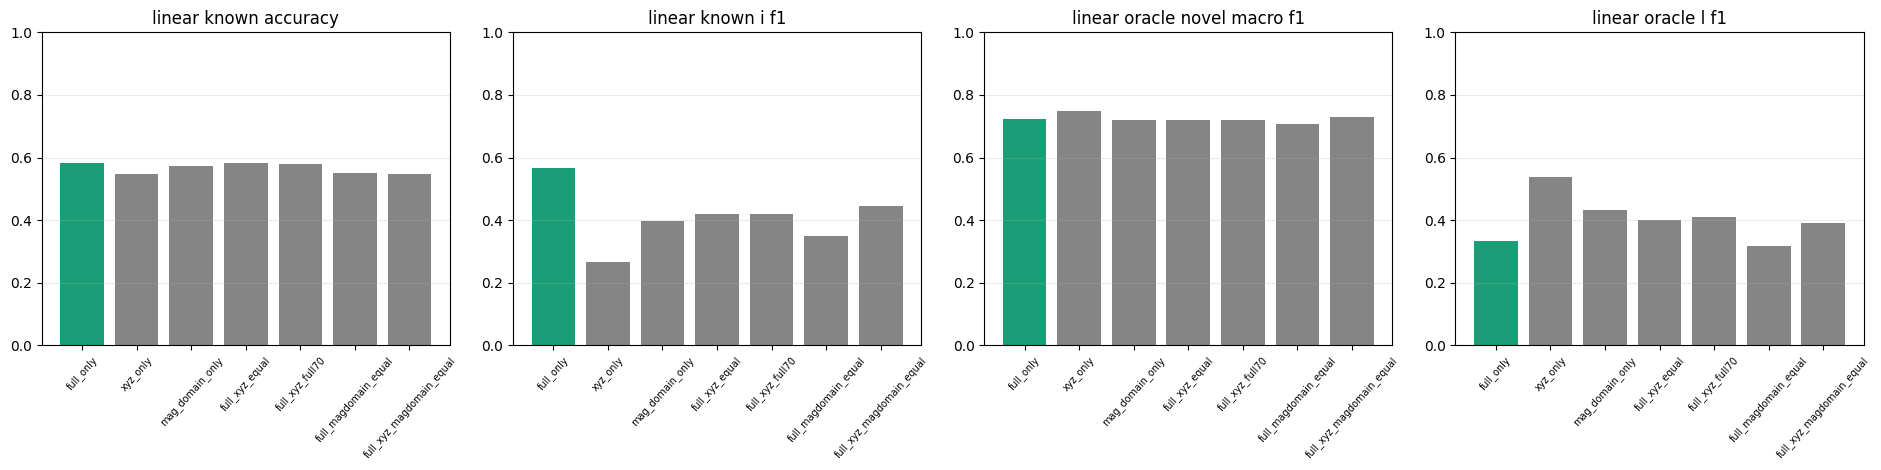

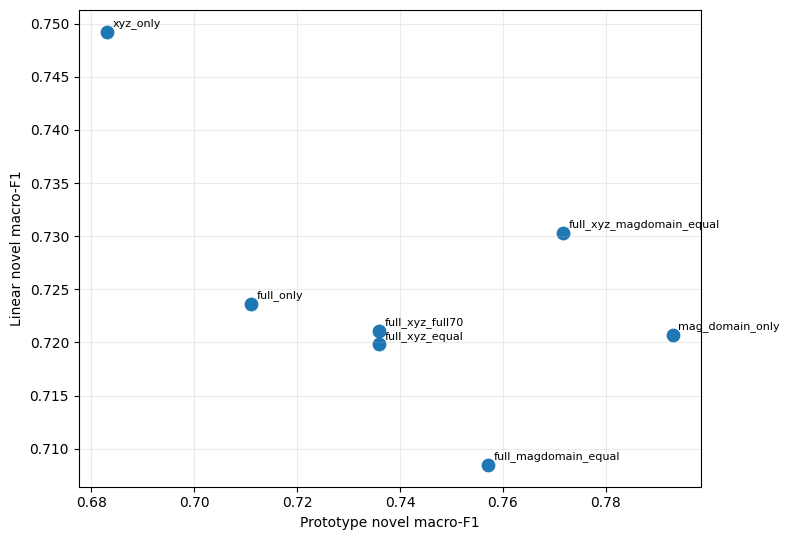

{
  "phase": "Phase 2C",
  "selected_fusion": "full_only",
  "selection": {
    "model": "full_only",
    "linear_accuracy": 0.4233088650479954,
    "linear_macro_f1": 0.36845873196675044,
    "linear_macro_f1_std": 0.11425625678527498,
    "linear_i_f1": 0.5688499334079358,
    "linear_ece": 0.313035594857722,
    "prototype_accuracy": 0.3320308676830416,
    "prototype_macro_f1": 0.26169308788239354,
    "selection_score": 0.3547681558124847
  },
  "selected_results": {
    "model": "full_only",
    "selected_on_development": true,
    "linear_known_accuracy": 0.583030303030303,
    "linear_known_macro_f1": 0.5879115602988636,
    "linear_known_i_f1": 0.5666666666666667,
    "linear_known_ece": 0.2679632837738848,
    "linear_oracle_novel_macro_f1": 0.723603704606059,
    "linear_oracle_l_f1": 0.33191489361702126,
    "linear_combined_macro_f1": 0.5786848141818219,
    "prototype_known_accuracy": 0.3878787878787879,
    "prototype_known_macro_f1": 0.3287230150568731,
    "prototype_k

525

In [8]:
fig,axes=plt.subplots(1,4,figsize=(19,4.8))
metrics=['linear_known_accuracy','linear_known_i_f1','linear_oracle_novel_macro_f1','linear_oracle_l_f1']
for ax,metric in zip(axes,metrics):
    colors=['#1b9e77' if m==SELECTED_FUSION else '#858585' for m in results.model]
    ax.bar(results.model,results[metric],color=colors);ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=48,labelsize=7);ax.set_ylim(0,1);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2c_fusion_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(8,5.5));ax.scatter(results.prototype_oracle_novel_macro_f1,results.linear_oracle_novel_macro_f1,s=80)
for row in results.itertuples():ax.annotate(row.model,(row.prototype_oracle_novel_macro_f1,row.linear_oracle_novel_macro_f1),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('Prototype novel macro-F1');ax.set_ylabel('Linear novel macro-F1');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2c_linear_vs_prototype.png',dpi=180,bbox_inches='tight');plt.show()

selected=results[results.model==SELECTED_FUSION].iloc[0];seldev=selection[selection.model==SELECTED_FUSION].iloc[0]
gates={
 'G1_frozen_phase2b_encoders':True,
 'G2_selected_only_on_development_known_labels':bool(selected.selected_on_development),
 'G3_cross_subject_variance':bool(seldev.linear_macro_f1_std<=CFG.loso_std_gate),
 'G4_linear_known_accuracy':bool(selected.linear_known_accuracy>=CFG.known_accuracy_gate),
 'G5_linear_known_I_f1':bool(selected.linear_known_i_f1>=CFG.known_i_f1_gate),
 'G6_linear_novel_macro_f1':bool(selected.linear_oracle_novel_macro_f1>=CFG.novel_macro_f1_gate),
 'G7_linear_novel_L_f1':bool(selected.linear_oracle_l_f1>=CFG.novel_l_f1_gate),
 'G8_prototype_known_macro_f1':bool(selected.prototype_known_macro_f1>=CFG.prototype_known_macro_gate),
 'G9_prototype_novel_macro_f1':bool(selected.prototype_oracle_novel_macro_f1>=CFG.prototype_novel_macro_gate),
 'G10_artifacts_complete':bool(len(selection)==len(FUSION_SPECS) and len(results)==len(FUSION_SPECS) and len(groupcv)>0)}
engineering_pass=bool(all(gates.values()))

def native(v):
    if isinstance(v,(np.bool_,bool)):return bool(v)
    if isinstance(v,(np.floating,float)):return float(v)
    if isinstance(v,(np.integer,int)):return int(v)
    return v
decision={'phase':'Phase 2C','selected_fusion':SELECTED_FUSION,
 'selection':{k:native(v) for k,v in seldev.to_dict().items()},'selected_results':{k:native(v) for k,v in selected.to_dict().items()},
 'gates':gates,'engineering_pass':engineering_pass,'rerun_phase1c_exploratory':engineering_pass,
 'confirmatory_claim_allowed':False,'requires_independent_dataset_confirmation':True,
 'evaluation_status':'Exploratory because the current evaluation subjects informed the Phase 2C design. Fusion selection itself used development known labels only.',
 'fusion_spec':{'branches':list(FUSION_SPECS[SELECTED_FUSION][0]),'weights':[float(w) for w in FUSION_SPECS[SELECTED_FUSION][1]]},'config':asdict(CFG)}
(OUT/'phase2c_decision.json').write_text(json.dumps(decision,indent=2));print(json.dumps(decision,indent=2))
(OUT/'phase2c_selected_fusion.json').write_text(json.dumps({'selected_fusion':SELECTED_FUSION,'fusion_spec':decision['fusion_spec'],'selection':decision['selection']},indent=2))


In [9]:
report=f"""# FedVocabHAR Phase 2C Decision Report

## Decision

**Selected fusion:** {SELECTED_FUSION}

**Engineering gates passed:** {engineering_pass}

**Exploratory Phase 1C rerun:** {decision['rerun_phase1c_exploratory']}

**Confirmatory claim allowed from this evaluation:** False

## Development selection

- LOSO linear macro-F1: {seldev.linear_macro_f1:.4f}
- LOSO subject SD: {seldev.linear_macro_f1_std:.4f}
- LOSO activity-I F1: {seldev.linear_i_f1:.4f}
- LOSO prototype macro-F1: {seldev.prototype_macro_f1:.4f}

## Exploratory frozen diagnostics

- Linear known accuracy: {selected.linear_known_accuracy:.4f}
- Linear activity-I F1: {selected.linear_known_i_f1:.4f}
- Linear novel macro-F1: {selected.linear_oracle_novel_macro_f1:.4f}
- Linear activity-L F1: {selected.linear_oracle_l_f1:.4f}
- Prototype known macro-F1: {selected.prototype_known_macro_f1:.4f}
- Prototype novel macro-F1: {selected.prototype_oracle_novel_macro_f1:.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nThese results are exploratory because the existing evaluation subjects informed the fusion design. An independent dataset or preregistered outer evaluation is required for confirmatory paper claims.\n'
(OUT/'FedVocabHAR_Phase2C_Decision_Report.md').write_text(report);print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 2C Decision Report

## Decision

**Selected fusion:** full_only

**Engineering gates passed:** False

**Exploratory Phase 1C rerun:** False

**Confirmatory claim allowed from this evaluation:** False

## Development selection

- LOSO linear macro-F1: 0.3685
- LOSO subject SD: 0.1143
- LOSO activity-I F1: 0.5688
- LOSO prototype macro-F1: 0.2617

## Exploratory frozen diagnostics

- Linear known accuracy: 0.5830
- Linear activity-I F1: 0.5667
- Linear novel macro-F1: 0.7236
- Linear activity-L F1: 0.3319
- Prototype known macro-F1: 0.3287
- Prototype novel macro-F1: 0.7110

## Gates

- G1_frozen_phase2b_encoders: **True**
- G2_selected_only_on_development_known_labels: **True**
- G3_cross_subject_variance: **False**
- G4_linear_known_accuracy: **False**
- G5_linear_known_I_f1: **True**
- G6_linear_novel_macro_f1: **True**
- G7_linear_novel_L_f1: **False**
- G8_prototype_known_macro_f1: **False**
- G9_prototype_novel_macro_f1: **True**
- G10_artifacts_complete: **True

## Interpretation

- If every engineering gate passes, rerun Phase 1C as an exploratory end-to-end integration test using the selected fused representation.
- If linear gates pass but prototype gates fail, do not proceed: integration depends on distances and prototype geometry.
- If L improves while known accuracy falls, the fusion weights must be selected inside nested subject folds; evaluation subjects must not determine them.
- Regardless of the result, validate the frozen Phase 2C recipe on an independent HAR dataset before using it as confirmatory evidence in the paper.
